In [1]:

import pandas as pd
import numpy as np

print("Python este pregătit pentru analiza Veridion!")


Python este pregătit pentru analiza Veridion!


In [2]:

from google.colab import files

uploaded = files.upload()


Saving chile-limited-fields.zip to chile-limited-fields.zip


In [3]:

!pip -q install pyarrow

import zipfile
import pyarrow.parquet as pq
from pathlib import Path

zip_path = "/content/chile-limited-fields.zip"

with zipfile.ZipFile(zip_path, "r") as archive:
    parquet_files = [
        name for name in archive.namelist()
        if name.endswith(".parquet")
    ]

    print("Fișiere găsite:", parquet_files)

    if not parquet_files:
        raise ValueError("Nu am găsit fișiere Parquet!")

    archive.extract(parquet_files[0], "/content/data")

parquet_path = Path("/content/data") / parquet_files[0]

parquet_file = pq.ParquetFile(parquet_path)

print("\nNumăr total de rânduri:",
      parquet_file.metadata.num_rows)

print("Număr total de coloane:",
      len(parquet_file.schema_arrow.names))

print("\nLista coloanelor:")
for column in parquet_file.schema_arrow:
    print(column.name, ":", column.type)


Fișiere găsite: ['chile-limited-fields/part-00000-6c72d195-7ba3-438c-9388-9f3cfdbb47bd-c000.snappy.parquet']

Număr total de rânduri: 476615
Număr total de coloane: 9

Lista coloanelor:
company_id : string
naics6 : struct<attribute: string, value: string, score: float, sources: list<element: string>>
short_description : string
employee_count : string
estimated_employees_count : struct<min_count: int32, max_count: int32, score: float>
revenue : string
modeled_revenue : int64
addresses : list<element: struct<country_code: string, country_name: string, region_code: string, region_name: string, city: string, city_district: string, continent_code: string, continent_name: string, state_district: string, road: string, postcode: string, po_box: string, house_number: string, entrance: string, is_json_ld_address: bool, l_rank: int32, level: string, main_location: bool, occurrences: int32, only_location: bool, score: int32, staircase: string, suburb: string, timezone: string, unit: string, valid_

In [4]:

import pandas as pd

# Citim coloanele necesare pentru verificarea inițială
columns = [
    "company_id",
    "naics6",
    "employee_count",
    "estimated_employees_count",
    "revenue",
    "modeled_revenue",
    "addresses"
]

df = pd.read_parquet(parquet_path, columns=columns)

print("Dimensiunea datelor:", df.shape)

print("\nCompanii unice:")
print(df["company_id"].nunique())

print("\nID-uri duplicate:")
print(df["company_id"].duplicated().sum())

print("\nValori lipsă pe coloane (%):")
print((df.isna().mean() * 100).round(2))

print("\nExemple de date:")
print(df[[
    "company_id",
    "employee_count",
    "revenue",
    "modeled_revenue"
]].head(5))


Dimensiunea datelor: (476615, 7)

Companii unice:
476615

ID-uri duplicate:
0

Valori lipsă pe coloane (%):
company_id                    0.00
naics6                        7.18
employee_count               87.87
estimated_employees_count    31.35
revenue                      99.41
modeled_revenue              64.52
addresses                     0.00
dtype: float64

Exemple de date:
                             company_id employee_count revenue  \
0  66b5e3cf-0aa1-11ef-a030-775ed0899596           None    None   
1  5ba651ba-0df8-11ef-a3d3-1f818e822e6f           None    None   
2  77fe09e6-cea0-11ed-8e7a-232f2c818e90           None    None   
3  7acdaa83-02d2-11ed-aafe-b30df4d3d978           None    None   
4  b9b7d03e-93e4-11eb-86dd-ffbd1b53140e             54  270000   

   modeled_revenue  
0              NaN  
1              NaN  
2         171878.0  
3              NaN  
4        2822340.0  


In [5]:

# Extragem codul industriei din structura NAICS
def extract_naics(value):
    if isinstance(value, dict):
        return value.get("value")
    return None

df["naics_code"] = df["naics6"].apply(extract_naics)

print("Companii cu NAICS valid:")
print(df["naics_code"].notna().sum())

print("\nPrimele 15 coduri NAICS:")
print(df["naics_code"].value_counts().head(15))

print("\nExemple de structuri NAICS:")
print(df["naics6"].dropna().head(3).tolist())


Companii cu NAICS valid:
442374

Primele 15 coduri NAICS:
naics_code
722511 Full-Service Restaurants                                                   27432
721110 Hotels (except Casino Hotels) and Motels                                   14942
445110 Supermarkets and Other Grocery Retailers (except Convenience Retailers)    13499
458110 Clothing and Clothing Accessories Retailers                                12226
622110 General Medical and Surgical Hospitals                                      9100
812112 Beauty Salons                                                               9060
531210 Offices of Real Estate Agents and Brokers                                   8150
541511 Custom Computer Programming Services                                        7789
722410 Drinking Places (Alcoholic Beverages)                                       6199
621210 Offices of Dentists                                                         6035
541611 Administrative Management and General Manage

In [6]:

# Explore geographic data

import numpy as np

# Verificăm cum arată adresele
print("Exemple de adrese:")

for address in df["addresses"].head(5):
    print(address)
    print("---")

# Verificăm câte companii au adrese
def has_address(value):
    if isinstance(value, (list, np.ndarray)):
        return len(value) > 0
    return False

df["has_address"] = df["addresses"].apply(has_address)

print("\nCompanii cu cel puțin o adresă:")
print(df["has_address"].sum())

print("\nProcent companii cu adresă:")
print(round(df["has_address"].mean() * 100, 2), "%")


Exemple de adrese:
[{'country_code': 'cl', 'country_name': 'Chile', 'region_code': 'cl-co', 'region_name': 'Región de Coquimbo', 'city': 'Coquimbo', 'city_district': None, 'continent_code': None, 'continent_name': None, 'state_district': None, 'road': 'Las Margaritas', 'postcode': '1700000', 'po_box': None, 'house_number': '450', 'entrance': None, 'is_json_ld_address': False, 'l_rank': None, 'level': None, 'main_location': None, 'occurrences': 1.0, 'only_location': None, 'score': 5.0, 'staircase': None, 'suburb': 'La Florida', 'timezone': None, 'unit': None, 'valid_zip_code': True, 'city_has_first_letter_upper_case': True, 'latitude': -29.9817611, 'longitude': -71.341942, 'raw_text': 'Las Margaritas 450, 1790999 Coquimbo, Chile', 'tokens': {'country': array(['chile'], dtype=object), 'region': array([], dtype=object), 'city': array(['coquimbo'], dtype=object), 'postcode': array([], dtype=object), 'road': array(['las margaritas', 'regi?n de coquimbo'], dtype=object), 'number': array(['45

In [7]:

# Extract geographic regions

import numpy as np
import pandas as pd

def extract_region(addresses):
    if not isinstance(addresses, (list, np.ndarray)):
        return None

    for address in addresses:
        if isinstance(address, dict):
            region = address.get("region_name")
            if region is not None and str(region).strip():
                return str(region).strip()

    return None

df["region"] = df["addresses"].apply(extract_region)

print("Companii cu regiune identificată:")
print(df["region"].notna().sum())

print("\nProcent cu regiune identificată:")
print(round(df["region"].notna().mean() * 100, 2), "%")

print("\nNumăr de regiuni distincte:")
print(df["region"].nunique())

print("\nTop 20 regiuni:")
print(df["region"].value_counts().head(20))


Companii cu regiune identificată:
420005

Procent cu regiune identificată:
88.12 %

Număr de regiuni distincte:
1072

Top 20 regiuni:
region
Región Metropolitana de Santiago                    171833
Región de Valparaíso                                 37797
Región del Biobío                                    24240
Santiago Metropolitan Region                         20024
Región de la Araucanía                               18781
Región de Los Lagos                                  18733
Región de Coquimbo                                   17831
Región del Maule                                     17762
Región del Libertador General Bernardo O'Higgins     15822
Región de Antofagasta                                10964
Región de Ñuble                                       7750
Región de Los Ríos                                    7556
Región de Tarapacá                                    6319
Region of Magallanes and Chilean Antarctica           5227
Región de Atacama                

In [8]:

# Investigate region codes

import numpy as np

def extract_region_code(addresses):
    if not isinstance(addresses, (list, np.ndarray)):
        return None

    for address in addresses:
        if isinstance(address, dict):
            code = address.get("region_code")
            if code is not None and str(code).strip():
                return str(code).strip().lower()

    return None

df["region_code"] = df["addresses"].apply(
    extract_region_code
)

print("Companii cu cod de regiune:")
print(df["region_code"].notna().sum())

print("\nNumăr de coduri distincte:")
print(df["region_code"].nunique())

print("\nCele mai frecvente 25 de coduri:")
print(df["region_code"].value_counts().head(25))


Companii cu cod de regiune:
418713

Număr de coduri distincte:
1037

Cele mai frecvente 25 de coduri:
region_code
cl-rm     190952
cl-vs      40569
cl-bi      25950
cl-ll      19903
cl-ar      19755
cl-ml      18678
cl-co      18675
cl-li      16738
cl-an      11814
cl-nb       8073
cl-lr       7935
cl-ta       6759
cl-ma       5212
cl-at       4594
cl-ap       3569
cl-ai       3316
ar-c         761
us-fl        739
us-ca        652
es-md        436
pe-lim       417
us-ny        415
ar-b         366
es-ct        354
us-tx        280
Name: count, dtype: int64


In [9]:

import numpy as np
import pandas as pd

# Explorăm adresele fără să modificăm datele originale.

def inspect_addresses(addresses):
    if not isinstance(addresses, (list, np.ndarray)):
        return pd.Series({
            "has_chile_address": False,
            "chile_region_count": 0,
            "has_multiple_regions": False
        })

    chile_regions = set()
    has_chile = False

    for address in addresses:
        if not isinstance(address, dict):
            continue

        country = str(
            address.get("country_code") or ""
        ).strip().lower()

        region = str(
            address.get("region_code") or ""
        ).strip().lower()

        if country == "cl":
            has_chile = True

            if region.startswith("cl-"):
                chile_regions.add(region)

    return pd.Series({
        "has_chile_address": has_chile,
        "chile_region_count": len(chile_regions),
        "has_multiple_regions": len(chile_regions) > 1
    })

geo_check = df["addresses"].apply(inspect_addresses)

print("Companii cu adresă în Chile:")
print(geo_check["has_chile_address"].sum())

print("\nCompanii cu regiune chiliană:")
print((geo_check["chile_region_count"] > 0).sum())

print("\nCompanii cu mai multe regiuni chiliene:")
print(geo_check["has_multiple_regions"].sum())

print("\nDistribuția numărului de regiuni:")
print(
    geo_check["chile_region_count"]
    .value_counts()
    .sort_index()
    .head(15)
)


Companii cu adresă în Chile:
476615

Companii cu regiune chiliană:
418320

Companii cu mai multe regiuni chiliene:
13680

Distribuția numărului de regiuni:
chile_region_count
0      58295
1     404640
2       9947
3       1752
4        651
5        369
6        259
7        165
8        126
9        115
10        68
11        60
12        60
13        40
14        26
Name: count, dtype: int64


In [10]:

# Validate Chilean region codes

valid_regions = {
    "cl-ai", "cl-an", "cl-ap", "cl-ar",
    "cl-at", "cl-bi", "cl-co", "cl-li",
    "cl-ll", "cl-lr", "cl-ma", "cl-ml",
    "cl-nb", "cl-rm", "cl-ta", "cl-vs"
}

def get_chile_regions(addresses):
    regions = set()

    for address in addresses:
        if not isinstance(address, dict):
            continue

        country = str(
            address.get("country_code") or ""
        ).strip().lower()

        code = str(
            address.get("region_code") or ""
        ).strip().lower()

        if country == "cl" and code.startswith("cl-"):
            regions.add(code)

    return regions

df["chile_regions"] = df["addresses"].apply(
    get_chile_regions
)

all_codes = set().union(*df["chile_regions"])

print("Coduri chiliene identificate:")
print(sorted(all_codes))

print("\nCoduri care nu sunt în lista celor 16 regiuni:")
print(sorted(all_codes - valid_regions))

print("\nCompanii cu cel puțin o regiune validă:")
print(
    df["chile_regions"].apply(
        lambda x: bool(x & valid_regions)
    ).sum()
)


Coduri chiliene identificate:
['cl-ai', 'cl-an', 'cl-ap', 'cl-ar', 'cl-at', 'cl-bi', 'cl-co', 'cl-li', 'cl-ll', 'cl-lr', 'cl-ma', 'cl-ml', 'cl-nb', 'cl-rm', 'cl-ta', 'cl-vs']

Coduri care nu sunt în lista celor 16 regiuni:
[]

Companii cu cel puțin o regiune validă:
418320


In [11]:

# Inspect NAICS classifications

import numpy as np

def count_naics(value):
    if isinstance(value, (list, np.ndarray)):
        return len(value)
    if isinstance(value, dict):
        return 1
    return 0

df["naics_count"] = df["naics6"].apply(count_naics)

print("Număr de clasificări NAICS per companie:")
print(
    df["naics_count"]
    .value_counts()
    .sort_index()
    .head(20)
)

print("\nCompanii cu mai multe clasificări:")
print((df["naics_count"] > 1).sum())

print("\nExemplu de clasificări multiple:")

multiple = df.loc[df["naics_count"] > 1, "naics6"]

if not multiple.empty:
    for item in multiple.iloc[0][:5]:
        print(item)


Număr de clasificări NAICS per companie:
naics_count
0     34241
1    442374
Name: count, dtype: int64

Companii cu mai multe clasificări:
0

Exemplu de clasificări multiple:


In [12]:

# Verificăm structura reală NAICS

example = df["naics6"].dropna().iloc[0]

print("Tipul structurii:")
print(type(example))

print("\nConținutul structurii:")
print(example)


Tipul structurii:
<class 'dict'>

Conținutul structurii:
{'attribute': 'naics6', 'value': '812111 Barber Shops', 'score': 0.5972550511360168, 'sources': array(['aggregator'], dtype=object)}


In [13]:

# Inspect NAICS scores

import pandas as pd

# Verificăm tipurile de date
print("Tipurile valorilor NAICS:")
print(df["naics6"].apply(lambda x: type(x).__name__).value_counts())

# Extragem scorurile fără să modificăm structura originală
df["naics_score"] = df["naics6"].apply(
    lambda x: x.get("score") if isinstance(x, dict) else None
)

df["naics_score"] = pd.to_numeric(
    df["naics_score"], errors="coerce"
)

print("\nStatistici pentru scorurile NAICS:")
print(df["naics_score"].describe())

print("\nCompanii cu scor disponibil:")
print(df["naics_score"].notna().sum())

print("\nCompanii cu scor >= 0.5:")
print((df["naics_score"] >= 0.5).sum())

print("\nCompanii cu scor >= 0.8:")
print((df["naics_score"] >= 0.8).sum())

print("\nScoruri în afara intervalului 0-1:")
print(
    (
        df["naics_score"].notna()
        & ~df["naics_score"].between(0, 1)
    ).sum()
)


Tipurile valorilor NAICS:
naics6
dict        442374
NoneType     34241
Name: count, dtype: int64

Statistici pentru scorurile NAICS:
count    442374.000000
mean          0.692478
std           0.229941
min           0.106179
25%           0.466560
50%           0.653139
75%           0.950000
max           1.000000
Name: naics_score, dtype: float64

Companii cu scor disponibil:
442374

Companii cu scor >= 0.5:
293949

Companii cu scor >= 0.8:
195227

Scoruri în afara intervalului 0-1:
0


In [14]:

# Extract broad NAICS sectors

import pandas as pd
import re

def extract_naics_code(value):
    if not isinstance(value, dict):
        return None

    raw = str(value.get("value") or "").strip()
    match = re.match(r"^(\d{6})(?!\d)", raw)

    return match.group(1) if match else None

def get_naics_sector(code):
    if not isinstance(code, str):
        return None

    prefix = int(code[:2])

    if 31 <= prefix <= 33:
        return "Manufacturing"
    if 44 <= prefix <= 45:
        return "Retail Trade"
    if 48 <= prefix <= 49:
        return "Transportation and Warehousing"

    sectors = {
        11: "Agriculture",
        21: "Mining",
        22: "Utilities",
        23: "Construction",
        42: "Wholesale Trade",
        51: "Information",
        52: "Finance and Insurance",
        53: "Real Estate",
        54: "Professional and Technical Services",
        55: "Management of Companies",
        56: "Administrative and Support Services",
        61: "Educational Services",
        62: "Health Care and Social Assistance",
        71: "Arts and Entertainment",
        72: "Accommodation and Food Services",
        81: "Other Services",
        92: "Public Administration"
    }

    return sectors.get(prefix)

df["naics_code"] = df["naics6"].apply(
    extract_naics_code
)

df["sector"] = df["naics_code"].apply(
    get_naics_sector
)

print("Companii cu sector identificat:")
print(df["sector"].notna().sum())

print("\nCompanii cu NAICS, dar sector neidentificat:")
print(
    (
        df["naics6"].notna()
        & df["sector"].isna()
    ).sum()
)

print("\nDistribuția sectoarelor:")
print(df["sector"].value_counts())

print("\nNumăr de sectoare distincte:")
print(df["sector"].nunique())


Companii cu sector identificat:
442374

Companii cu NAICS, dar sector neidentificat:
0

Distribuția sectoarelor:
sector
Retail Trade                           81433
Accommodation and Food Services        62674
Professional and Technical Services    54009
Manufacturing                          38330
Other Services                         35443
Health Care and Social Assistance      33150
Arts and Entertainment                 18109
Construction                           16733
Administrative and Support Services    15324
Real Estate                            15108
Educational Services                   14714
Wholesale Trade                        13720
Information                            13312
Transportation and Warehousing         12262
Finance and Insurance                   6022
Utilities                               4523
Agriculture                             4037
Public Administration                   1949
Mining                                  1522
Name: count, dtype: int64

In [15]:

# Prepare regional industry analysis

# Păstrăm companiile cu exact o regiune validă
# și cu un sector industrial identificat.

def valid_company_regions(regions):
    if not isinstance(regions, set):
        return set()
    return regions & valid_regions

df["valid_regions"] = df["chile_regions"].apply(
    valid_company_regions
)

mask = (
    (df["valid_regions"].apply(len) == 1)
    & df["sector"].notna()
)

analysis_df = df.loc[
    mask,
    ["company_id", "valid_regions", "sector", "naics_score"]
].copy()

analysis_df["region_code"] = (
    analysis_df["valid_regions"].apply(
        lambda regions: next(iter(regions))
    )
)

print("Companii incluse în analiza regională:")
print(len(analysis_df))

print("\nCompanii pe regiuni:")
print(
    analysis_df["region_code"]
    .value_counts()
)

print("\nNumăr de regiuni:")
print(analysis_df["region_code"].nunique())

print("\nCompanii unice:")
print(analysis_df["company_id"].nunique())


Companii incluse în analiza regională:
372763

Companii pe regiuni:
region_code
cl-rm    181804
cl-vs     37166
cl-bi     23050
cl-ar     18343
cl-ll     18018
cl-co     16919
cl-ml     16304
cl-li     14504
cl-an     10791
cl-nb      7057
cl-lr      7045
cl-ta      6165
cl-ma      5115
cl-at      4223
cl-ap      3263
cl-ai      2996
Name: count, dtype: int64

Număr de regiuni:
16

Companii unice:
372763


In [16]:

# Regional sector distribution

import pandas as pd

# Numărul companiilor din fiecare sector și regiune
regional_counts = pd.crosstab(
    analysis_df["region_code"],
    analysis_df["sector"]
)

# Ponderea fiecărui sector în totalul regiunii
regional_shares = (
    regional_counts.div(
        regional_counts.sum(axis=1),
        axis=0
    ) * 100
)

# Ponderea sectoarelor în întregul eșantion
national_shares = (
    analysis_df["sector"]
    .value_counts(normalize=True) * 100
)

print("Ponderea sectoarelor în eșantion (%):")
print(national_shares.round(2))

print("\nPrimele 3 sectoare pentru fiecare regiune:")

for region in regional_shares.index:
    print(f"\n{region}")
    print(
        regional_shares.loc[region]
        .sort_values(ascending=False)
        .head(3)
        .round(2)
    )


Ponderea sectoarelor în eșantion (%):
sector
Retail Trade                           18.78
Accommodation and Food Services        16.17
Professional and Technical Services    11.22
Other Services                          8.46
Manufacturing                           8.15
Health Care and Social Assistance       7.82
Arts and Entertainment                  4.03
Construction                            3.66
Real Estate                             3.33
Administrative and Support Services     3.27
Wholesale Trade                         3.01
Educational Services                    3.01
Transportation and Warehousing          2.77
Information                             2.49
Finance and Insurance                   1.29
Utilities                               0.99
Agriculture                             0.90
Public Administration                   0.34
Mining                                  0.32
Name: proportion, dtype: float64

Primele 3 sectoare pentru fiecare regiune:

cl-ai
sector
Accommoda

In [17]:

# Location Quotient analysis

import numpy as np
import pandas as pd

# Calculăm LQ pentru fiecare regiune și sector
lq = regional_shares.div(
    national_shares,
    axis=1
)

# Verificăm dacă rezultatele sunt finite
assert np.isfinite(lq.to_numpy()).all()

# Ne concentrăm momentan pe sectorul NAICS 72
sector = "Accommodation and Food Services"

results = pd.DataFrame({
    "region": lq.index,
    "companies": regional_counts[sector],
    "regional_share": regional_shares[sector],
    "lq": lq[sector]
})

results = results.sort_values(
    "lq", ascending=False
)

print("Ponderea sectorului în eșantion:")
print(round(national_shares[sector], 2), "%")

print("\nSpecializarea regională NAICS 72:")
print(results.round(2).to_string(index=False))

print("\nVerificare:")
print("Total companii din sector:",
      regional_counts[sector].sum())


Ponderea sectorului în eșantion:
16.17 %

Specializarea regională NAICS 72:
region  companies  regional_share   lq
 cl-ai       1025           34.21 2.12
 cl-lr       1941           27.55 1.70
 cl-ma       1340           26.20 1.62
 cl-ar       4645           25.32 1.57
 cl-ll       4490           24.92 1.54
 cl-ap        794           24.33 1.50
 cl-at        974           23.06 1.43
 cl-nb       1593           22.57 1.40
 cl-an       2320           21.50 1.33
 cl-vs       7831           21.07 1.30
 cl-ta       1278           20.73 1.28
 cl-ml       3339           20.48 1.27
 cl-li       2956           20.38 1.26
 cl-co       3325           19.65 1.22
 cl-bi       3641           15.80 0.98
 cl-rm      18785           10.33 0.64

Verificare:
Total companii din sector: 60277


In [18]:

# Accommodation vs Food Services

# Adăugăm codurile NAICS detaliate
analysis_df["naics_code"] = df.loc[
    analysis_df.index, "naics_code"
]

# Selectăm companiile din sectorul 72
sector72 = analysis_df[
    analysis_df["sector"] == "Accommodation and Food Services"
].copy()

# Clasificăm activitățile
sector72["subsector"] = sector72["naics_code"].str[:3].map({
    "721": "Accommodation",
    "722": "Food Services"
})

# Verificăm clasificările
print("Subsectoare identificate:")
print(sector72["subsector"].value_counts(dropna=False))

# Comparăm Aysén și Santiago
comparison = sector72[
    sector72["region_code"].isin(["cl-ai", "cl-rm"])
]

counts = pd.crosstab(
    comparison["region_code"],
    comparison["subsector"]
)

shares = counts.div(
    counts.sum(axis=1), axis=0
) * 100

print("\nNumăr de companii:")
print(counts)

print("\nDistribuția în interiorul sectorului 72 (%):")
print(shares.round(2))


Subsectoare identificate:
subsector
Food Services    39108
Accommodation    21169
Name: count, dtype: int64

Număr de companii:
subsector    Accommodation  Food Services
region_code                              
cl-ai                  692            333
cl-rm                 3843          14942

Distribuția în interiorul sectorului 72 (%):
subsector    Accommodation  Food Services
region_code                              
cl-ai                67.51          32.49
cl-rm                20.46          79.54


In [19]:

# Accommodation across all Chilean regions

import pandas as pd

# Folosim datasetul regional deja validat
regional_data = analysis_df.copy()

# Identificăm companiile din subsectorul 721
regional_data["is_accommodation"] = (
    regional_data["naics_code"].str[:3] == "721"
)

# Calculăm indicatorii pentru fiecare regiune
accommodation_by_region = (
    regional_data
    .groupby("region_code")
    .agg(
        total_companies=("company_id", "nunique"),
        accommodation_companies=("is_accommodation", "sum")
    )
)

# Calculăm ponderea cazării în fiecare regiune
accommodation_by_region["accommodation_share"] = (
    accommodation_by_region["accommodation_companies"]
    / accommodation_by_region["total_companies"]
    * 100
)

# Calculăm ponderea la nivelul întregului eșantion
overall_share = (
    regional_data["is_accommodation"].mean() * 100
)

# Calculăm Location Quotient
accommodation_by_region["accommodation_lq"] = (
    accommodation_by_region["accommodation_share"]
    / overall_share
)

# Sortăm după specializarea relativă
accommodation_by_region = (
    accommodation_by_region
    .sort_values("accommodation_lq", ascending=False)
)

print("Ponderea cazării în eșantion:")
print(round(overall_share, 2), "%")

print("\nComparația celor 16 regiuni:")
print(accommodation_by_region.round(2).to_string())

print("\nVerificări:")
print("Regiuni analizate:", len(accommodation_by_region))

print(
    "Total companii:",
    accommodation_by_region["total_companies"].sum()
)

print(
    "Total companii de cazare:",
    accommodation_by_region["accommodation_companies"].sum()
)


Ponderea cazării în eșantion:
5.68 %

Comparația celor 16 regiuni:
             total_companies  accommodation_companies  accommodation_share  accommodation_lq
region_code                                                                                 
cl-ai                   2996                      692                23.10              4.07
cl-ma                   5115                      887                17.34              3.05
cl-lr                   7045                     1044                14.82              2.61
cl-ar                  18343                     2544                13.87              2.44
cl-ll                  18018                     2402                13.33              2.35
cl-an                  10791                      982                 9.10              1.60
cl-vs                  37166                     3092                 8.32              1.46
cl-at                   4223                      343                 8.12              1.43
cl-

In [20]:

# Sensitivity analysis for accommodation

import pandas as pd

results = []

for threshold in [0, 0.5, 0.8]:

    subset = analysis_df[
        analysis_df["naics_score"].notna()
        & (analysis_df["naics_score"] >= threshold)
    ].copy()

    subset["is_accommodation"] = (
        subset["naics_code"].str[:3] == "721"
    )

    baseline = subset["is_accommodation"].mean()

    for region in ["cl-ai", "cl-ma", "cl-lr", "cl-rm"]:

        region_df = subset[
            subset["region_code"] == region
        ]

        total = len(region_df)
        accommodation = int(
            region_df["is_accommodation"].sum()
        )

        share = (
            accommodation / total
            if total > 0 else float("nan")
        )

        lq = (
            share / baseline
            if baseline > 0 else float("nan")
        )

        results.append({
            "threshold": threshold,
            "region": region,
            "total_companies": total,
            "accommodation_companies": accommodation,
            "accommodation_share_pct": share * 100,
            "lq": lq
        })

sensitivity_df = pd.DataFrame(results)

print(
    sensitivity_df.round(2).to_string(index=False)
)


 threshold region  total_companies  accommodation_companies  accommodation_share_pct   lq
       0.0  cl-ai             2996                      692                    23.10 4.07
       0.0  cl-ma             5115                      887                    17.34 3.05
       0.0  cl-lr             7045                     1044                    14.82 2.61
       0.0  cl-rm           181804                     3843                     2.11 0.37
       0.5  cl-ai             1617                      512                    31.66 4.83
       0.5  cl-ma             3114                      702                    22.54 3.44
       0.5  cl-lr             3633                      762                    20.97 3.20
       0.5  cl-rm           129439                     2953                     2.28 0.35
       0.8  cl-ai              902                      286                    31.71 5.16
       0.8  cl-ma             2068                      533                    25.77 4.20
       0.8

In [21]:

# Sensitivity analysis across all 16 regions

import pandas as pd

all_results = []

for threshold in [0, 0.5, 0.8]:

    subset = analysis_df[
        analysis_df["naics_score"].notna()
        & (analysis_df["naics_score"] >= threshold)
    ].copy()

    subset["is_accommodation"] = (
        subset["naics_code"].str[:3] == "721"
    )

    baseline = subset["is_accommodation"].mean()

    grouped = subset.groupby("region_code").agg(
        total_companies=("company_id", "nunique"),
        accommodation_companies=("is_accommodation", "sum")
    )

    grouped["share_pct"] = (
        grouped["accommodation_companies"]
        / grouped["total_companies"] * 100
    )

    grouped["lq"] = (
        grouped["share_pct"] / (baseline * 100)
    )

    grouped["threshold"] = threshold

    all_results.append(grouped.reset_index())

robustness_all = pd.concat(
    all_results, ignore_index=True
)

for threshold in [0, 0.5, 0.8]:

    print(f"\nTOP 5 REGIUNI — prag {threshold}")

    result = robustness_all[
        robustness_all["threshold"] == threshold
    ].sort_values("lq", ascending=False)

    print(
        result[
            [
                "region_code",
                "total_companies",
                "accommodation_companies",
                "share_pct",
                "lq"
            ]
        ].head(5).round(2).to_string(index=False)
    )



TOP 5 REGIUNI — prag 0
region_code  total_companies  accommodation_companies  share_pct   lq
      cl-ai             2996                      692      23.10 4.07
      cl-ma             5115                      887      17.34 3.05
      cl-lr             7045                     1044      14.82 2.61
      cl-ar            18343                     2544      13.87 2.44
      cl-ll            18018                     2402      13.33 2.35

TOP 5 REGIUNI — prag 0.5
region_code  total_companies  accommodation_companies  share_pct   lq
      cl-ai             1617                      512      31.66 4.83
      cl-ma             3114                      702      22.54 3.44
      cl-lr             3633                      762      20.97 3.20
      cl-ar             9881                     1961      19.85 3.03
      cl-ll             9912                     1739      17.54 2.67

TOP 5 REGIUNI — prag 0.8
region_code  total_companies  accommodation_companies  share_pct   lq
      cl-ai   

In [23]:

#  Verificarea companiilor multiregionale

# Verificăm structura coloanei
print("Exemple de regiuni:")
print(df["chile_regions"].head(5).to_string())

# Numărăm regiunile distincte pentru fiecare companie
def count_regions(value):
    if isinstance(value, (list, tuple, set)):
        return len(set(value))
    return 0

df["chile_region_count"] = (
    df["chile_regions"].apply(count_regions)
)

print("\nDistribuția numărului de regiuni:")
print(
    df["chile_region_count"]
    .value_counts()
    .sort_index()
    .to_string()
)

print("\nCompanii cu mai multe regiuni:")
print((df["chile_region_count"] > 1).sum())

print("\nCompanii cu exact o regiune:")
print((df["chile_region_count"] == 1).sum())

print("\nCompanii fără regiune:")
print((df["chile_region_count"] == 0).sum())


Exemple de regiuni:
0    {cl-co}
1    {cl-rm}
2    {cl-ma}
3         {}
4    {cl-rm}

Distribuția numărului de regiuni:
chile_region_count
0      58295
1     404640
2       9947
3       1752
4        651
5        369
6        259
7        165
8        126
9        115
10        68
11        60
12        60
13        40
14        26
15        22
16        20

Companii cu mai multe regiuni:
13680

Companii cu exact o regiune:
404640

Companii fără regiune:
58295


In [24]:

# Includerea companiilor multiregionale

import pandas as pd

# Păstrăm companiile cu cel puțin o regiune validă
multi_df = df[
    df["chile_region_count"] >= 1
].copy()

# Verificăm că identificatorii sunt unici
assert multi_df["company_id"].is_unique

# Extragem o singură clasificare sectorială
# pentru fiecare companie, folosind maparea
# deja validată din analiza principală.

sector_map = (
    analysis_df[["naics_code", "sector"]]
    .dropna()
    .drop_duplicates()
    .set_index("naics_code")["sector"]
    .to_dict()
)

# Folosim codurile NAICS deja extrase în df
multi_df["sector"] = (
    multi_df["naics_code"].map(sector_map)
)

# Selectăm doar companiile clasificate
multi_df = multi_df[
    multi_df["sector"].notna()
].copy()

# Transformăm fiecare regiune într-un rând separat
multi_expanded = multi_df.explode(
    "chile_regions"
).rename(
    columns={"chile_regions": "region_code"}
)

# Eliminăm eventuale perechi duplicate
multi_expanded = multi_expanded.drop_duplicates(
    subset=["company_id", "region_code"]
)

# Identificăm companiile de cazare
multi_expanded["is_accommodation"] = (
    multi_expanded["naics_code"]
    .astype(str)
    .str[:3]
    .eq("721")
)

print("Companii unice incluse:")
print(multi_df["company_id"].nunique())

print("\nRelații companie-regiune:")
print(len(multi_expanded))

print("\nRegiuni identificate:")
print(multi_expanded["region_code"].nunique())

print("\nCompanii de cazare unice:")
print(
    multi_df.loc[
        multi_df["naics_code"].astype(str).str[:3].eq("721"),
        "company_id"
    ].nunique()
)


Companii unice incluse:
386132

Relații companie-regiune:
409816

Regiuni identificate:
region_code    1018
region_code      16
dtype: int64

Companii de cazare unice:
22034


In [25]:

# Corectarea structurii regionale

# Pornim de la multi_df, nu de la multi_expanded
multi_expanded = multi_df.drop(
    columns=["region_code"],
    errors="ignore"
).explode("chile_regions").copy()

# Redenumim coloana cu regiunile valide
multi_expanded = multi_expanded.rename(
    columns={"chile_regions": "region_code"}
)

# Eliminăm perechile duplicate companie-regiune
multi_expanded = multi_expanded.drop_duplicates(
    subset=["company_id", "region_code"]
)

# Identificăm companiile de cazare
multi_expanded["is_accommodation"] = (
    multi_expanded["naics_code"]
    .astype(str)
    .str[:3]
    .eq("721")
)

# Verificări obligatorii
print("Coloane region_code:")
print(
    multi_expanded.columns.tolist().count("region_code")
)

print("\nNumăr regiuni distincte:")
print(multi_expanded["region_code"].nunique())

print("\nCoduri regionale:")
print(sorted(multi_expanded["region_code"].unique()))

print("\nCompanii unice:")
print(multi_expanded["company_id"].nunique())

print("\nRelații companie-regiune:")
print(len(multi_expanded))

print("\nPerechi duplicate:")
print(
    multi_expanded.duplicated(
        ["company_id", "region_code"]
    ).sum()
)

# Validare
assert (
    multi_expanded.columns.tolist().count("region_code")
    == 1
)

assert multi_expanded["region_code"].nunique() == 16

assert not multi_expanded.duplicated(
    ["company_id", "region_code"]
).any()

print("\nVALIDARE FINALIZATĂ")


Coloane region_code:
1

Număr regiuni distincte:
16

Coduri regionale:
['cl-ai', 'cl-an', 'cl-ap', 'cl-ar', 'cl-at', 'cl-bi', 'cl-co', 'cl-li', 'cl-ll', 'cl-lr', 'cl-ma', 'cl-ml', 'cl-nb', 'cl-rm', 'cl-ta', 'cl-vs']

Companii unice:
386132

Relații companie-regiune:
409816

Perechi duplicate:
0

VALIDARE FINALIZATĂ


In [26]:

# Compararea specializării regionale

import pandas as pd

# Calculăm indicatorii regionali
extended_results = (
    multi_expanded
    .groupby("region_code")
    .agg(
        total_companies=("company_id", "nunique"),
        accommodation_companies=("is_accommodation", "sum")
    )
)

# Ponderea cazării în fiecare regiune
extended_results["share_pct"] = (
    extended_results["accommodation_companies"]
    / extended_results["total_companies"]
    * 100
)

# Ponderea de referință în analiza extinsă
extended_baseline = (
    multi_expanded["is_accommodation"].mean()
)

# Location Quotient
extended_results["lq"] = (
    extended_results["share_pct"]
    / (extended_baseline * 100)
)

# Comparație cu analiza inițială
comparison = accommodation_by_region[
    ["accommodation_share", "accommodation_lq"]
].join(
    extended_results[["share_pct", "lq"]],
    how="inner"
)

comparison.columns = [
    "initial_share",
    "initial_lq",
    "extended_share",
    "extended_lq"
]

comparison["lq_difference"] = (
    comparison["extended_lq"]
    - comparison["initial_lq"]
)

comparison = comparison.sort_values(
    "initial_lq", ascending=False
)

print("Pondere de referință extinsă:")
print(round(extended_baseline * 100, 2), "%")

print("\nComparația celor 16 regiuni:")
print(comparison.round(2).to_string())

print("\nTop 5 după LQ extins:")
print(
    extended_results
    .sort_values("lq", ascending=False)
    .head(5)
    .round(2)
    .to_string()
)


Pondere de referință extinsă:
5.65 %

Comparația celor 16 regiuni:
             initial_share  initial_lq  extended_share  extended_lq  lq_difference
region_code                                                                       
cl-ai                23.10        4.07           20.84         3.69          -0.38
cl-ma                17.34        3.05           15.60         2.76          -0.29
cl-lr                14.82        2.61           14.04         2.48          -0.13
cl-ar                13.87        2.44           12.91         2.28          -0.16
cl-ll                13.33        2.35           12.20         2.16          -0.19
cl-an                 9.10        1.60            8.04         1.42          -0.18
cl-vs                 8.32        1.46            8.35         1.48           0.01
cl-at                 8.12        1.43            7.39         1.31          -0.12
cl-nb                 8.11        1.43            8.41         1.49           0.06
cl-co               

In [27]:

# Audit final al clasificărilor

import pandas as pd

# Companiile cu regiune chiliană identificată
eligible = df[
    df["chile_region_count"] >= 1
].copy()

# Verificăm existența clasificărilor NAICS
eligible["has_naics"] = (
    eligible["naics_code"].notna()
)

# Verificăm dacă sectorul a fost mapat
eligible["mapped_sector"] = (
    eligible["naics_code"].map(sector_map)
)

print("Companii cu regiune validă:")
print(len(eligible))

print("\nCompanii cu NAICS:")
print(eligible["has_naics"].sum())

print("\nCompanii cu sector mapat:")
print(eligible["mapped_sector"].notna().sum())

# Coduri NAICS care nu au fost mapate
unmapped = eligible[
    eligible["has_naics"]
    & eligible["mapped_sector"].isna()
]

print("\nCompanii cu NAICS nemapat:")
print(len(unmapped))

print("\nExemple de coduri nemapate:")
print(
    unmapped["naics_code"]
    .value_counts()
    .head(10)
)

# Verificarea codurilor de cazare
print("\nCompanii cu NAICS 721:")
print(
    eligible["naics_code"]
    .astype("string")
    .str.startswith("721", na=False)
    .sum()
)


Companii cu regiune validă:
418320

Companii cu NAICS:
386136

Companii cu sector mapat:
386132

Companii cu NAICS nemapat:
4

Exemple de coduri nemapate:
naics_code
483114    1
325194    1
483211    1
336213    1
Name: count, dtype: int64

Companii cu NAICS 721:
22034


In [28]:

# Auditul final al maparii NAICS

import pandas as pd

# Codurile care nu au fost mapate anterior
unmapped_codes = [
    "483114", "325194", "483211", "336213"
]

# Clasificarea sectoriala NAICS
def get_naics_sector(code):
    if pd.isna(code):
        return None

    code = str(code).strip()

    if len(code) < 2 or not code[:2].isdigit():
        return None

    prefix = int(code[:2])

    if 31 <= prefix <= 33:
        return "Manufacturing"
    elif 44 <= prefix <= 45:
        return "Retail Trade"
    elif 48 <= prefix <= 49:
        return "Transportation and Warehousing"

    return None

print("Verificarea codurilor nemapate:\n")

for code in unmapped_codes:
    print(code, "->", get_naics_sector(code))

print("\nCompanii afectate:")
print(
    eligible[
        eligible["naics_code"].astype("string").isin(
            unmapped_codes
        )
    ][["company_id", "naics_code", "mapped_sector"]]
    .to_string(index=False)
)


Verificarea codurilor nemapate:

483114 -> Transportation and Warehousing
325194 -> Manufacturing
483211 -> Transportation and Warehousing
336213 -> Manufacturing

Companii afectate:
                          company_id naics_code mapped_sector
e280cad6-93e4-11eb-8e19-198fb02d6f96     483114           NaN
3c9d52c2-1236-11ec-9574-5d456f65b38e     325194           NaN
1a08a4a4-93e5-11eb-8e19-198fb02d6f96     483211           NaN
592ef510-5953-11ec-a2c3-69a286ba0a19     336213           NaN


In [29]:

# Corectarea celor 4 companii

import pandas as pd

# Copie a datelor eligibile
corrected_df = eligible.copy()

# Pornim de la clasificarea existenta
corrected_df["sector"] = corrected_df["mapped_sector"]

# Completam doar cele 4 coduri nemapate
missing_mask = (
    corrected_df["sector"].isna()
    & corrected_df["naics_code"].notna()
)

corrected_df.loc[missing_mask, "sector"] = (
    corrected_df.loc[missing_mask, "naics_code"]
    .apply(get_naics_sector)
)

# Pastram doar companiile clasificate
corrected_df = corrected_df[
    corrected_df["sector"].notna()
].copy()

# Extindem regiunile
corrected_expanded = (
    corrected_df
    .drop(columns=["region_code"], errors="ignore")
    .explode("chile_regions")
    .rename(columns={"chile_regions": "region_code"})
    .drop_duplicates(["company_id", "region_code"])
)

# Identificam companiile de cazare
corrected_expanded["is_accommodation"] = (
    corrected_expanded["naics_code"]
    .astype("string")
    .str.startswith("721", na=False)
)

# Calculam indicatorii regionali
final_regions = (
    corrected_expanded
    .groupby("region_code")
    .agg(
        total_companies=("company_id", "nunique"),
        accommodation_companies=("is_accommodation", "sum")
    )
)

final_regions["share_pct"] = (
    final_regions["accommodation_companies"]
    / final_regions["total_companies"] * 100
)

baseline = (
    corrected_expanded["is_accommodation"].mean()
)

final_regions["lq"] = (
    final_regions["share_pct"] / (baseline * 100)
)

print("Companii unice:", corrected_df["company_id"].nunique())
print("Relatii companie-regiune:", len(corrected_expanded))
print("Regiuni:", len(final_regions))
print("Pondere nationala:", round(baseline * 100, 3), "%")

print("\nTop regiuni dupa LQ:")
print(
    final_regions
    .sort_values("lq", ascending=False)
    .round(3)
    .to_string()
)


Companii unice: 386136
Relatii companie-regiune: 409828
Regiuni: 16
Pondere nationala: 5.652 %

Top regiuni dupa LQ:
             total_companies  accommodation_companies  share_pct     lq
region_code                                                            
cl-ai                   3537                      737     20.837  3.687
cl-ma                   5969                      931     15.597   2.76
cl-lr                   8169                     1147     14.041  2.484
cl-ar                  20482                     2645     12.914  2.285
cl-ll                  20592                     2513     12.204  2.159
cl-nb                   8142                      685      8.413  1.489
cl-vs                  41473                     3462      8.348  1.477
cl-an                  12945                     1041      8.042  1.423
cl-at                   5035                      372      7.388  1.307
cl-co                  19273                     1396      7.243  1.282
cl-ml              

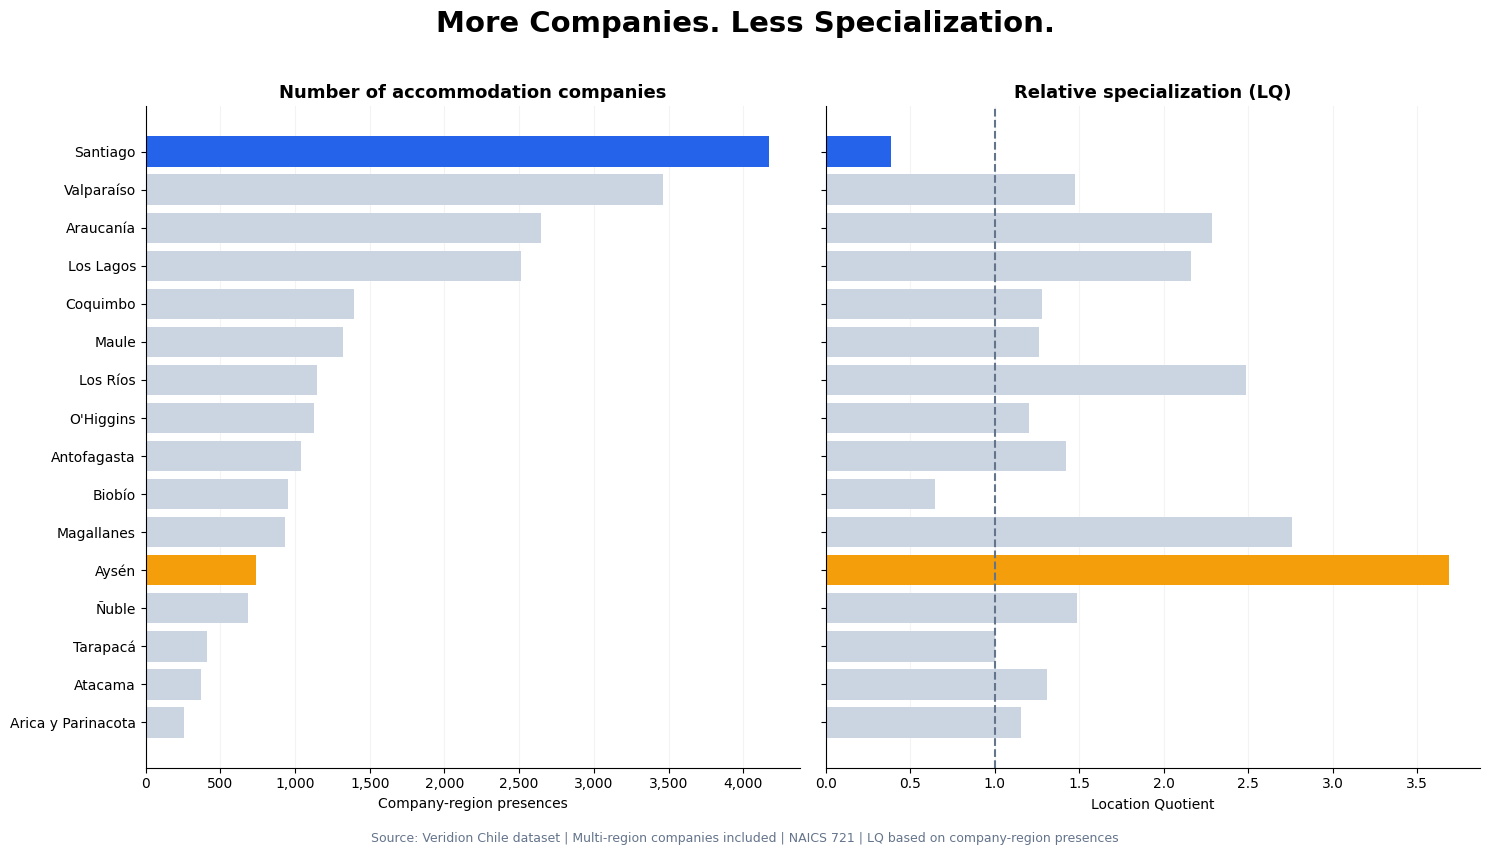

In [30]:

# More Companies. Less Specialization.

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import FuncFormatter

region_names = {
    "cl-ai": "Aysén",
    "cl-an": "Antofagasta",
    "cl-ap": "Arica y Parinacota",
    "cl-ar": "Araucanía",
    "cl-at": "Atacama",
    "cl-bi": "Biobío",
    "cl-co": "Coquimbo",
    "cl-li": "O'Higgins",
    "cl-ll": "Los Lagos",
    "cl-lr": "Los Ríos",
    "cl-ma": "Magallanes",
    "cl-ml": "Maule",
    "cl-nb": "Ñuble",
    "cl-rm": "Santiago",
    "cl-ta": "Tarapacá",
    "cl-vs": "Valparaíso"
}

plot_df = final_regions.copy()
plot_df["region"] = plot_df.index.map(region_names)

assert plot_df["region"].notna().all()
assert len(plot_df) == 16

plot_df = plot_df.sort_values(
    "accommodation_companies",
    ascending=True
)

fig, axes = plt.subplots(
    1, 2, figsize=(15, 8),
    sharey=True,
    gridspec_kw={"width_ratios": [1, 1]}
)

colors = [
    "#F59E0B" if r == "Aysén"
    else "#2563EB" if r == "Santiago"
    else "#CBD5E1"
    for r in plot_df["region"]
]

axes[0].barh(
    plot_df["region"],
    plot_df["accommodation_companies"],
    color=colors
)

axes[0].set_title(
    "Number of accommodation companies",
    fontsize=13, fontweight="bold"
)
axes[0].set_xlabel("Company-region presences")
axes[0].xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x:,.0f}")
)

axes[1].barh(
    plot_df["region"],
    plot_df["lq"],
    color=colors
)

axes[1].axvline(
    1, color="#64748B",
    linestyle="--", linewidth=1.5
)

axes[1].set_title(
    "Relative specialization (LQ)",
    fontsize=13, fontweight="bold"
)
axes[1].set_xlabel("Location Quotient")

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", alpha=0.15)
    ax.set_axisbelow(True)

fig.suptitle(
    "More Companies. Less Specialization.",
    fontsize=21, fontweight="bold", y=1.02
)

fig.text(
    0.5, -0.02,
    "Source: Veridion Chile dataset | "
    "Multi-region companies included | "
    "NAICS 721 | LQ based on company-region presences",
    ha="center", fontsize=9, color="#64748B"
)

plt.tight_layout()
plt.savefig(
    "veridion_main_chart.png",
    dpi=300, bbox_inches="tight"
)
plt.show()


In [31]:

# Evidentiem valorile pentru Santiago si Aysen
for i, (_, row) in enumerate(plot_df.iterrows()):
    if row["region"] in ["Santiago", "Aysén"]:
        axes[0].text(
            row["accommodation_companies"] + 35,
            i,
            f'{int(row["accommodation_companies"]):,}',
            va="center",
            fontsize=10,
            fontweight="bold"
        )

        axes[1].text(
            row["lq"] + 0.04,
            i,
            f'{row["lq"]:.2f}',
            va="center",
            fontsize=10,
            fontweight="bold"
        )

axes[0].set_xlim(
    0, plot_df["accommodation_companies"].max() * 1.16
)

axes[1].set_xlim(
    0, plot_df["lq"].max() * 1.16
)

fig.text(
    0.5, 0.96,
    "Santiago leads in company presence, "
    "while Aysén leads in relative specialization",
    ha="center",
    fontsize=11,
    color="#475569"
)


Text(0.5, 0.96, 'Santiago leads in company presence, while Aysén leads in relative specialization')

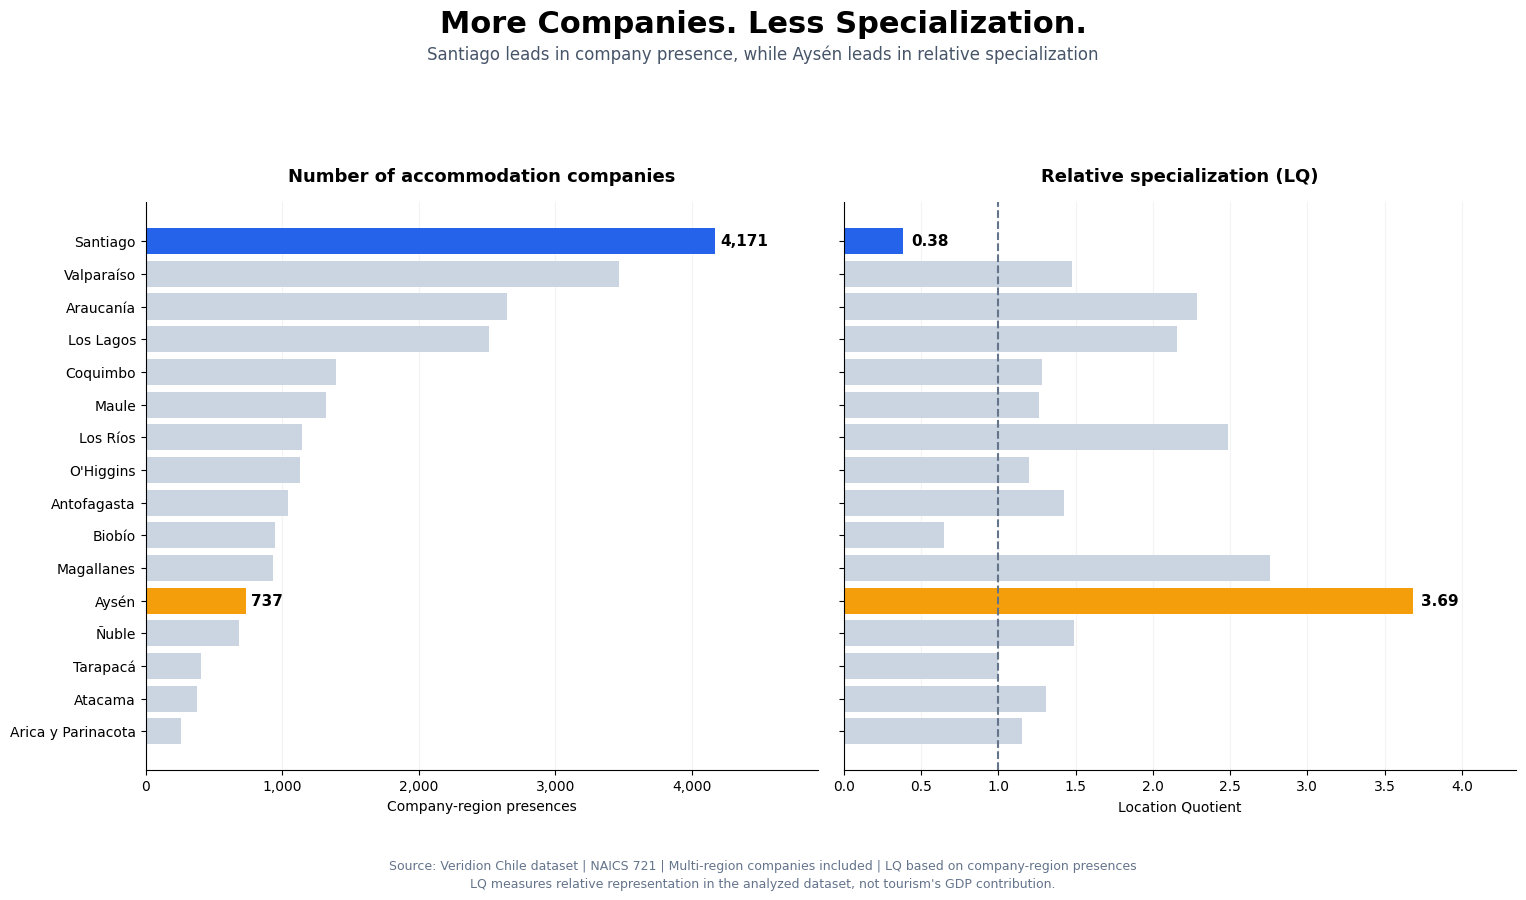

In [32]:

#  Grafic imbunatatit Veridion

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

region_names = {
    "cl-ai": "Aysén",
    "cl-an": "Antofagasta",
    "cl-ap": "Arica y Parinacota",
    "cl-ar": "Araucanía",
    "cl-at": "Atacama",
    "cl-bi": "Biobío",
    "cl-co": "Coquimbo",
    "cl-li": "O'Higgins",
    "cl-ll": "Los Lagos",
    "cl-lr": "Los Ríos",
    "cl-ma": "Magallanes",
    "cl-ml": "Maule",
    "cl-nb": "Ñuble",
    "cl-rm": "Santiago",
    "cl-ta": "Tarapacá",
    "cl-vs": "Valparaíso"
}

plot_df = final_regions.copy()
plot_df["region"] = plot_df.index.map(region_names)

assert len(plot_df) == 16
assert plot_df["region"].notna().all()

plot_df = plot_df.sort_values(
    "accommodation_companies",
    ascending=True
)

colors = [
    "#F59E0B" if r == "Aysén"
    else "#2563EB" if r == "Santiago"
    else "#CBD5E1"
    for r in plot_df["region"]
]

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 9),
    sharey=True
)

# Grafic 1: numarul companiilor
axes[0].barh(
    plot_df["region"],
    plot_df["accommodation_companies"],
    color=colors
)

axes[0].set_title(
    "Number of accommodation companies",
    fontsize=13,
    fontweight="bold",
    pad=15
)

axes[0].set_xlabel(
    "Company-region presences"
)

axes[0].xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x:,.0f}")
)

# Grafic 2: specializarea regionala
axes[1].barh(
    plot_df["region"],
    plot_df["lq"],
    color=colors
)

axes[1].axvline(
    1,
    color="#64748B",
    linestyle="--",
    linewidth=1.5
)

axes[1].set_title(
    "Relative specialization (LQ)",
    fontsize=13,
    fontweight="bold",
    pad=15
)

axes[1].set_xlabel("Location Quotient")

# Spatiu pentru etichete
axes[0].set_xlim(
    0,
    plot_df["accommodation_companies"].max() * 1.18
)

axes[1].set_xlim(
    0,
    plot_df["lq"].max() * 1.18
)

# Adaugam cifrele pentru Santiago si Aysen
for i, (_, row) in enumerate(plot_df.iterrows()):

    if row["region"] in ["Santiago", "Aysén"]:

        axes[0].text(
            row["accommodation_companies"] + 35,
            i,
            f'{int(row["accommodation_companies"]):,}',
            va="center",
            fontsize=11,
            fontweight="bold"
        )

        axes[1].text(
            row["lq"] + 0.05,
            i,
            f'{row["lq"]:.2f}',
            va="center",
            fontsize=11,
            fontweight="bold"
        )

# Aspect profesional
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="x", alpha=0.15)
    ax.set_axisbelow(True)

fig.suptitle(
    "More Companies. Less Specialization.",
    fontsize=22,
    fontweight="bold",
    y=0.98
)

fig.text(
    0.5, 0.925,
    "Santiago leads in company presence, "
    "while Aysén leads in relative specialization",
    ha="center",
    fontsize=12,
    color="#475569"
)

fig.text(
    0.5, 0.025,
    "Source: Veridion Chile dataset | "
    "NAICS 721 | Multi-region companies included | "
    "LQ based on company-region presences",
    ha="center",
    fontsize=9,
    color="#64748B"
)

fig.text(
    0.5, 0.005,
    "LQ measures relative representation in the "
    "analyzed dataset, not tourism's GDP contribution.",
    ha="center",
    fontsize=9,
    color="#64748B"
)

plt.tight_layout(rect=[0.02, 0.07, 0.98, 0.87])

plt.savefig(
    "veridion_main_chart_final.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


In [33]:

# Robustete NAICS in analiza extinsa

import pandas as pd
import numpy as np

required = [
    "company_id",
    "region_code",
    "naics_code",
    "naics_score",
    "is_accommodation"
]

missing = [
    c for c in required
    if c not in corrected_expanded.columns
]

if missing:
    raise KeyError(
        f"Coloane lipsa: {missing}. "
        "Trebuie sa verificam sursa scorurilor."
    )

base = corrected_expanded.copy()

# Pastram doar regiunile chiliene valide
valid_regions = {
    "cl-ai", "cl-an", "cl-ap", "cl-ar",
    "cl-at", "cl-bi", "cl-co", "cl-li",
    "cl-ll", "cl-lr", "cl-ma", "cl-ml",
    "cl-nb", "cl-rm", "cl-ta", "cl-vs"
}

base = base[
    base["region_code"].isin(valid_regions)
].copy()

base["naics_score"] = pd.to_numeric(
    base["naics_score"], errors="coerce"
)

# Verificam unicitatea perechilor
assert not base.duplicated(
    ["company_id", "region_code"]
).any()

results = []

for threshold in [0.0, 0.5, 0.8]:

    # Pragul 0 include toate scorurile disponibile
    sample = base[
        base["naics_score"].notna()
        & (base["naics_score"] >= threshold)
    ].copy()

    if sample.empty:
        raise ValueError("Esantion gol")

    national_share = sample[
        "is_accommodation"
    ].mean()

    if national_share == 0:
        raise ValueError(
            "Nu exista companii de cazare"
        )

    regional = sample.groupby(
        "region_code"
    ).agg(
        total_companies=("company_id", "nunique"),
        accommodation_companies=(
            "is_accommodation", "sum"
        )
    )

    regional["share_pct"] = (
        regional["accommodation_companies"]
        / regional["total_companies"] * 100
    )

    regional["lq"] = (
        regional["share_pct"]
        / (national_share * 100)
    )

    regional["threshold"] = threshold

    results.append(
        regional.reset_index()
    )

robustness_df = pd.concat(
    results, ignore_index=True
)

# Selectam top 5 din scenariul de baza
baseline_top5 = (
    robustness_df[
        robustness_df["threshold"] == 0.0
    ]
    .sort_values("lq", ascending=False)
    .head(5)["region_code"]
    .tolist()
)

print("Top 5 din scenariul de baza:")
print(baseline_top5)

print("\nComparatie LQ:")
comparison = (
    robustness_df[
        robustness_df["region_code"].isin(
            baseline_top5
        )
    ]
    .pivot(
        index="region_code",
        columns="threshold",
        values="lq"
    )
    .reindex(baseline_top5)
)

print(comparison.round(3))

print("\nDimensiunea esantioanelor:")
for threshold in [0.0, 0.5, 0.8]:
    sample = base[
        base["naics_score"].notna()
        & (base["naics_score"] >= threshold)
    ]
    print(
        f"Prag {threshold}: "
        f"{sample['company_id'].nunique():,} "
        "companii unice; "
        f"{len(sample):,} relatii"
    )


Top 5 din scenariul de baza:
['cl-ai', 'cl-ma', 'cl-lr', 'cl-ar', 'cl-ll']

Comparatie LQ:
threshold      0.0    0.5    0.8
region_code                     
cl-ai        3.687  4.071  4.055
cl-ma         2.76  2.953  3.389
cl-lr        2.484   2.85  2.257
cl-ar        2.285  2.688  2.709
cl-ll        2.159  2.327  2.054

Dimensiunea esantioanelor:
Prag 0.0: 386,136 companii unice; 409,828 relatii
Prag 0.5: 244,061 companii unice; 266,639 relatii
Prag 0.8: 155,986 companii unice; 174,361 relatii


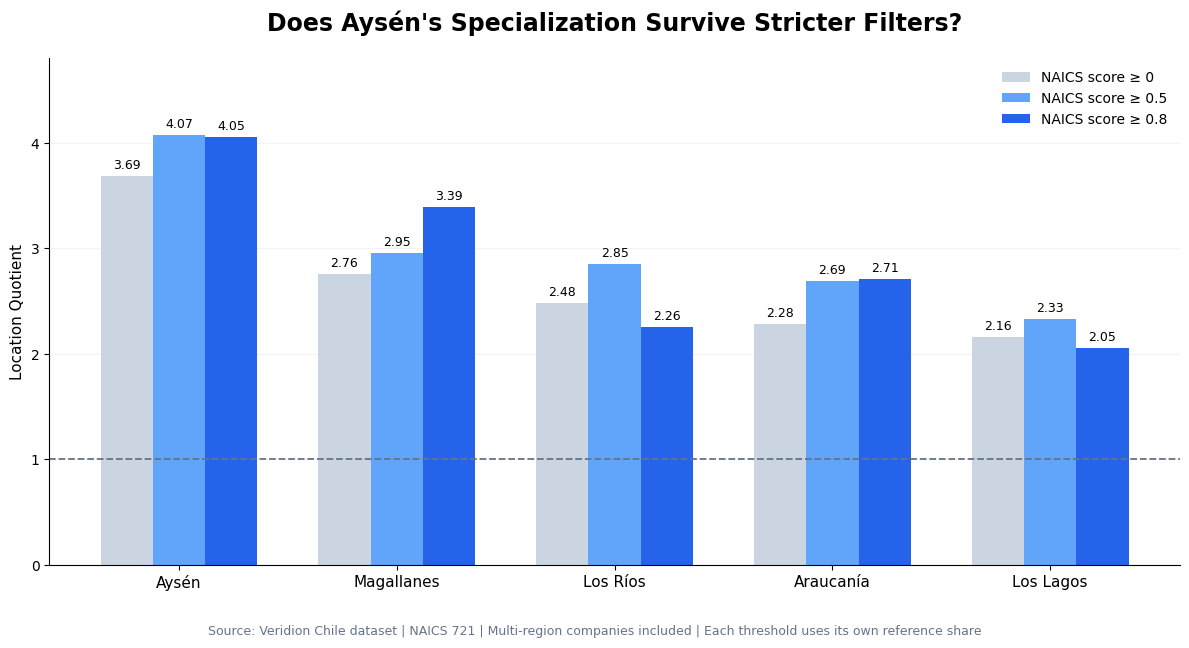

In [34]:

#  Robustness chart

import matplotlib.pyplot as plt
import numpy as np

region_labels = {
    "cl-ai": "Aysén",
    "cl-ma": "Magallanes",
    "cl-lr": "Los Ríos",
    "cl-ar": "Araucanía",
    "cl-ll": "Los Lagos"
}

chart_data = comparison.copy()
chart_data.index = chart_data.index.map(region_labels)

thresholds = [0.0, 0.5, 0.8]

x = np.arange(len(chart_data))
width = 0.24

fig, ax = plt.subplots(figsize=(12, 6.5))

colors = ["#CBD5E1", "#60A5FA", "#2563EB"]

for i, threshold in enumerate(thresholds):
    values = chart_data[threshold]

    bars = ax.bar(
        x + (i - 1) * width,
        values,
        width,
        label=f"NAICS score ≥ {threshold:g}",
        color=colors[i]
    )

    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.04,
            f"{height:.2f}",
            ha="center",
            va="bottom",
            fontsize=9
        )

ax.axhline(
    1,
    color="#64748B",
    linestyle="--",
    linewidth=1.3
)

ax.set_xticks(x)
ax.set_xticklabels(chart_data.index, fontsize=11)

ax.set_ylabel("Location Quotient", fontsize=11)
ax.set_ylim(0, chart_data.max().max() * 1.18)

ax.set_title(
    "Does Aysén's Specialization Survive Stricter Filters?",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.legend(frameon=False, loc="upper right")

ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.15)
ax.set_axisbelow(True)

fig.text(
    0.5, 0.015,
    "Source: Veridion Chile dataset | "
    "NAICS 721 | Multi-region companies included | "
    "Each threshold uses its own reference share",
    ha="center",
    fontsize=9,
    color="#64748B"
)

plt.tight_layout(rect=[0, 0.06, 1, 1])

plt.savefig(
    "veridion_robustness_chart.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


In [35]:

# FINAL METHODOLOGICAL AUDIT

import pandas as pd
import numpy as np

regions = {
    "cl-ai", "cl-an", "cl-ap", "cl-ar",
    "cl-at", "cl-bi", "cl-co", "cl-li",
    "cl-ll", "cl-lr", "cl-ma", "cl-ml",
    "cl-nb", "cl-rm", "cl-ta", "cl-vs"
}

data = corrected_expanded.copy()

# 1. Integritatea datelor
print("=== 1. DATA INTEGRITY ===")

print("Rows:", len(data))
print("Unique companies:", data.company_id.nunique())

duplicates = data.duplicated(
    ["company_id", "region_code"]
).sum()

print("Duplicate company-region pairs:", duplicates)

assert duplicates == 0
assert data["company_id"].notna().all()
assert data["region_code"].isin(regions).all()

# 2. Clasificarea NAICS
print("\n=== 2. NAICS VALIDATION ===")

naics = data["naics_code"].astype("string")

expected_accommodation = naics.str.startswith(
    "721", na=False
)

mismatches = (
    expected_accommodation !=
    data["is_accommodation"].astype(bool)
).sum()

print("Accommodation classification mismatches:",
      mismatches)

assert mismatches == 0

# 3. Recalcularea LQ
print("\n=== 3. LQ VALIDATION ===")

national_share = expected_accommodation.mean()

regional = data.groupby("region_code").agg(
    total=("company_id", "nunique"),
    accommodation=("is_accommodation", "sum")
)

regional["share"] = (
    regional["accommodation"] / regional["total"]
)

regional["lq_check"] = (
    regional["share"] / national_share
)

difference = (
    regional["lq_check"] -
    final_regions["lq"]
).abs().max()

print("National reference share:",
      round(national_share * 100, 4), "%")

print("Maximum LQ difference:", difference)

assert np.isclose(difference, 0, atol=1e-10)

# 4. Verificarea clasamentului
print("\n=== 4. REGIONAL RANKING ===")

ranking = regional.sort_values(
    "lq_check", ascending=False
)

print(ranking.head(5).round(4))

assert ranking.index[0] == "cl-ai"

# 5. Robustetea la praguri
print("\n=== 5. ROBUSTNESS ===")

for threshold in [0.0, 0.5, 0.8]:

    subset = robustness_df[
        np.isclose(
            robustness_df["threshold"], threshold
        )
    ]

    winner = subset.sort_values(
        "lq", ascending=False
    ).iloc[0]

    print(
        f"Threshold {threshold}: "
        f"{winner['region_code']} "
        f"(LQ={winner['lq']:.3f})"
    )

    assert winner["region_code"] == "cl-ai"

print("\nALL CHECKS PASSED")


=== 1. DATA INTEGRITY ===
Rows: 409828
Unique companies: 386136
Duplicate company-region pairs: 0

=== 2. NAICS VALIDATION ===
Accommodation classification mismatches: 0

=== 3. LQ VALIDATION ===
National reference share: 5.6519 %
Maximum LQ difference: 4.440892098500626e-16

=== 4. REGIONAL RANKING ===
             total  accommodation   share  lq_check
region_code                                        
cl-ai         3537            737  0.2084    3.6867
cl-ma         5969            931   0.156    2.7597
cl-lr         8169           1147  0.1404    2.4843
cl-ar        20482           2645  0.1291    2.2849
cl-ll        20592           2513   0.122    2.1592

=== 5. ROBUSTNESS ===
Threshold 0.0: cl-ai (LQ=3.687)
Threshold 0.5: cl-ai (LQ=4.071)
Threshold 0.8: cl-ai (LQ=4.055)

ALL CHECKS PASSED
